Avocado Prices adathalmaz elemzése


Mennyire jelezhető előre az avokádó ára trend, szezonalitás és régiós eltérések alapján, és mely időszakokban romlik el látványosan az előrejelzés?

A kutatás során ezekre a kérdésekre keressük a válaszokat. 
Mennyire jelezhető előre az avokádó ára?
1. Mennyire tudom megbecsülni a jövő heti árat? Segít, ha figyelembe veszem a trendet, az évszakot? 
2. Mekkora a bio avokádó felára? Megnézem, hogyan változik a felár a piacok között, és megpróbálom megbecsülni a következő hétre.
3. Mely időszakokban romlik el az előrejelzés? És ennek mi lehet az oka?

Az első és a harmadik kérdésben az amerikai országos (TotalUS) hagyományos heti átlagárat vizsgálom. A másodikhoz a bio és hagyományos árakat azonos piacon és héten párosítom. Az árakat USD/db-ban adom meg.

Forrás: Justin Kiggins Avocado Prices adathalmazát használom, amely a Hass Avocado Board amerikai bolti eladási adatain alapul. Egy sorban egy piac, heti avokádi eladási adati vannak (usd/db ár, bio e ?, méret, milyen kiszerelésben) Az adatok 2015 januárjától 2018 márciusáig tartanak.

Futtatáshoz az avocado.csv legyen a projekt data mappájában. 

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("data/avocado.csv")
df.head(10)

,Unnamed: 0,Date,AveragePrice,Total Volume,4046,4225,4770,Total Bags,Small Bags,Large Bags,XLarge Bags,type,year,region
0,0,2015-12-27,1.33,64236.62,1036.74,54454.85,48.16,8696.87,8603.62,93.25,0.0,conventional,2015,Albany
1,1,2015-12-20,1.35,54876.98,674.28,44638.81,58.33,9505.56,9408.07,97.49,0.0,conventional,2015,Albany
2,2,2015-12-13,0.93,118220.22,794.70,109149.67,130.50,8145.35,8042.21,103.14,0.0,conventional,2015,Albany
3,3,2015-12-06,1.08,78992.15,1132.00,71976.41,72.58,5811.16,5677.40,133.76,0.0,conventional,2015,Albany
4,4,2015-11-29,1.28,51039.60,941.48,43838.39,75.78,6183.95,5986.26,197.69,0.0,conventional,2015,Albany
5,5,2015-11-22,1.26,55979.78,1184.27,48067.99,43.61,6683.91,6556.47,127.44,0.0,conventional,2015,Albany
6,6,2015-11-15,0.99,83453.76,1368.92,73672.72,93.26,8318.86,8196.81,122.05,0.0,conventional,2015,Albany
7,7,2015-11-08,0.98,109428.33,703.75,101815.36,80.00,6829.22,6266.85,562.37,0.0,conventional,2015,Albany
8,8,2015-11-01,1.02,99811.42,1022.15,87315.57,85.34,11388.36,11104.53,283.83,0.0,conventional,2015,Albany
9,9,2015-10-25,1.07,74338.76,842.40,64757.44,113.00,8625.92,8061.47,564.45,0.0,conventional,2015,Albany


In [5]:
print("Sorok és oszlopok száma:", df.shape)
print("\nOszlopok nevei:", df.columns.tolist())
print("\nTermesztési típusok eloszlása:")
print(df['type'].value_counts())
print("Adattípusok:\n", df.dtypes)
print("\nAlapvető statisztikai mutatók:")
print(df[['AveragePrice', 'Total Volume', 'Total Bags', 'year']].describe())
print("\nHiányzó értékek száma oszloponként:\n", df.isnull().sum())
print("\nDuplikált sorok száma:", df.duplicated().sum())

Sorok és oszlopok száma: (18249, 14)

Oszlopok nevei: ['Unnamed: 0', 'Date', 'AveragePrice', 'Total Volume', '4046', '4225', '4770', 'Total Bags', 'Small Bags', 'Large Bags', 'XLarge Bags', 'type', 'year', 'region']

Termesztési típusok eloszlása:
type
conventional    9126
organic         9123
Name: count, dtype: int64
Adattípusok:
 Unnamed: 0        int64
Date                str
AveragePrice    float64
Total Volume    float64
4046            float64
4225            float64
4770            float64
Total Bags      float64
Small Bags      float64
Large Bags      float64
XLarge Bags     float64
type                str
year              int64
region              str
dtype: object

Alapvető statisztikai mutatók:
       AveragePrice  Total Volume    Total Bags          year
count  18249.000000  1.824900e+04  1.824900e+04  18249.000000
mean       1.405978  8.506440e+05  2.396392e+05   2016.147899
std        0.402677  3.453545e+06  9.862424e+05      0.939938
min        0.440000  8.456000e+01  

### Az adathalmazo bemutatása

**1. Az adathalmaz tartalma:**
A választott adathalmaz a Hass Avocado Board (HAB) hivatalos kiskereskedelmi eladási statisztikáiból származik (`avocado.csv`). Az adathalmaz az Egyesült Államok különböző régióiban 2015 és 2018 között értékesített avokádók heti árait és eladási mennyiségeit rögzíti.

**2. Változók:**
Az adathalmaz **18 249 rekordot (sort)** és **14 oszlopot (változót)** tartalmaz. 

| Változó | Magyarázat | Példa (első sor értékei) |
|---|---|---:|
| `Date` | A megfigyelési hét, ez mindig vasárnap. | `2015-12-27` |
| `region` | A piac vagy területi neve (állam is lehet, több várost egybefogó piac, vagy régiós összesítés). | `Albany` |
| `type` | Típus. `conventional` = hagyományos, `organic` = bio. | `conventional` |
| `year` | Külön eltárolva év. | `2015` |
| `AveragePrice` | Avokádó átlagos eladási ára, (usd/db). | 1,33 |
| `Total Volume` | Adott piacon, a teljes eladott mennyiség (minden méretből és zacskóból). | 64 236,62 |
| `4046` | Kis méretű, darabonként értékesített mennyiség. | 1 036,74 |
| `4225` | Nagy méretű, darabonként értékesített mennyiség. | 54 454,85 |
| `4770` | Extra nagy méretű, darabonként értékesített mennyiség. | 48,16 |
| `Total Bags` | Zacskós kiszerelésben értékesített összes mennyiség. | 8 696,87 |
| `Small Bags` | Kis zacskós kiszerelésben mennyiség. | 8 603,62 |
| `Large Bags` | Nagy zacskós kiszerelésben mennyiség. | 93,25 |
| `XLarge Bags` | Extra nagy zacskós kiszerelésben mennyiség. | 0 |
| `Unnamed: 0` | A CSV-be mentett régi sorindex, az értékei ismétlődnek, az elemzésből elhagyható. | 0 |





A teljes heti idősor hónapokra tagolva
Mindkét ábrán a CSV első és utolsó hete közötti összes ár szerepel. Minden pont egy hét, a függőleges vonalak és a dátumcímkék a hónapok kezdetét jelölik. Így a hétenkénti mozgás és a hónapok közötti különbség egyszerre látszik.

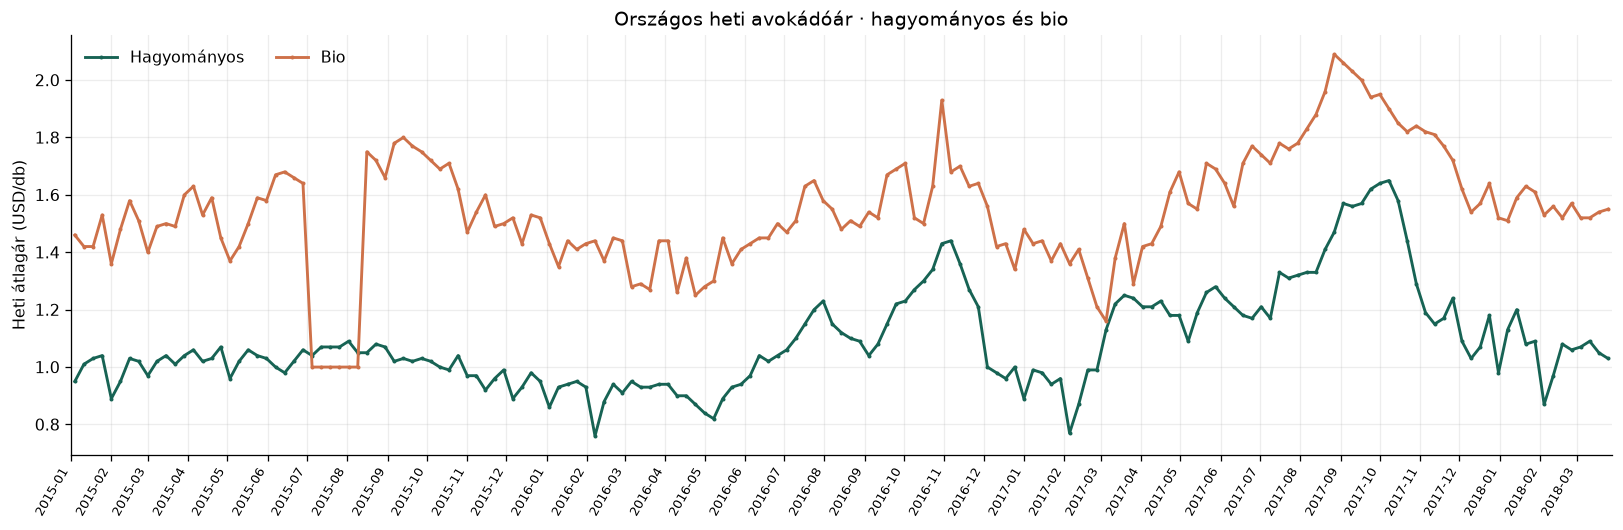

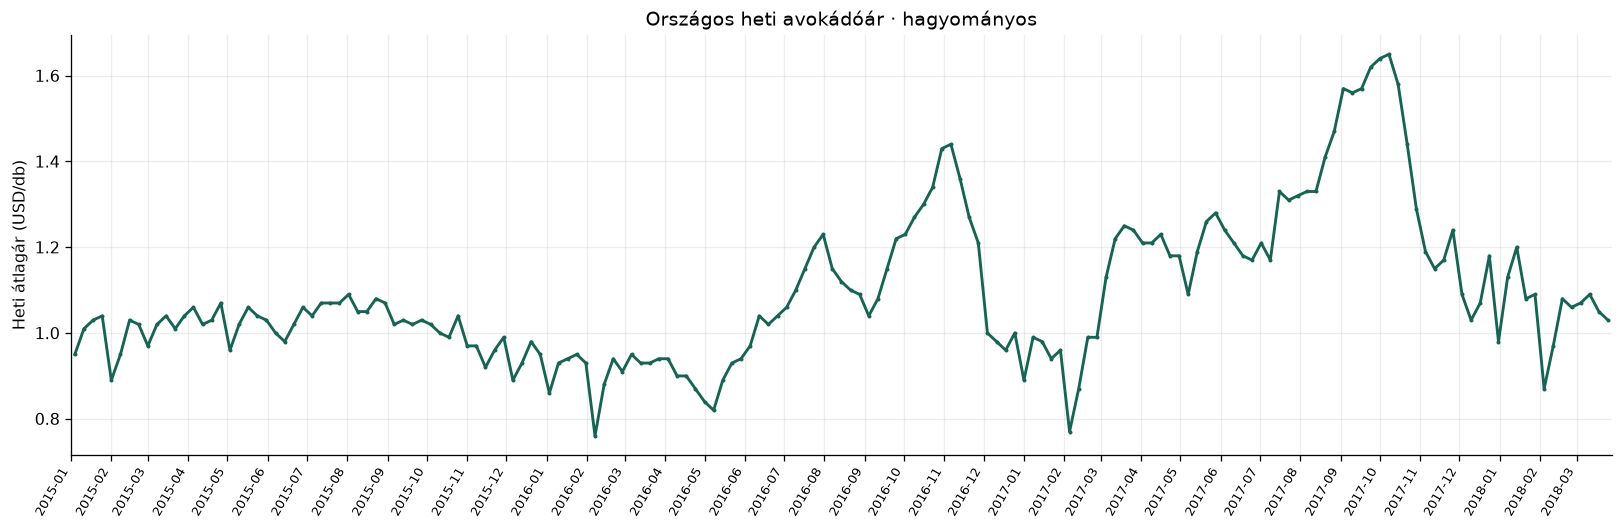

Első hét: 2015-01-04 | utolsó hét: 2018-03-25 | hetek száma: 169
Hagyományos csúcs: 2017-10-08, 1.65 USD/db.


In [23]:

from pathlib import Path
from IPython.display import display
from sklearn.linear_model import LinearRegression

plt.rcParams.update({
    "figure.dpi": 115, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.22, "axes.axisbelow": True,
})
ZOLD = "#176354"
NARANCS = "#ce7149"
SZURKE = "#555f70"
pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 145)

nyers = pd.read_csv(Path("data/avocado.csv"), parse_dates=["Date"])
adat = nyers.drop(columns="Unnamed: 0").rename(columns={
    "Date": "datum", "region": "piac", "type": "tipus",
    "AveragePrice": "ar", "Total Volume": "mennyiseg",
})
hetek = pd.date_range(adat["datum"].min(), adat["datum"].max(), freq="W-SUN", name="datum")
orszagos = adat.loc[adat["piac"] == "TotalUS"].copy()
us_arak = orszagos.pivot(index="datum", columns="tipus", values="ar").reindex(hetek)
us_hagy = us_arak["conventional"]

def havi_tengely(ax):
    elso_honap = hetek[0].replace(day=1)
    ax.set_xlim(elso_honap, hetek[-1] + pd.Timedelta(days=3))
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    plt.setp(ax.get_xticklabels(), rotation=60, ha="right", fontsize=8)
    ax.set_ylabel("Heti átlagár (USD/db)")


fig, ax = plt.subplots(figsize=(14, 4.5), layout="constrained")
ax.plot(us_hagy, color=ZOLD, lw=1.8, marker=".", ms=3, label="Hagyományos")
ax.plot(us_arak["organic"], color=NARANCS, lw=1.8, marker=".", ms=3, label="Bio")
havi_tengely(ax)
ax.set_title("Országos heti avokádóár · hagyományos és bio")
ax.legend(frameon=False, ncol=2)
plt.show()

fig, ax = plt.subplots(figsize=(14, 4.5), layout="constrained")
ax.plot(us_hagy, color=ZOLD, lw=1.8, marker=".", ms=3)
havi_tengely(ax)
ax.set_title("Országos heti avokádóár · hagyományos")
plt.show()

print(f"Első hét: {hetek[0].date()} | utolsó hét: {hetek[-1].date()} | hetek száma: {len(hetek)}")
print(f"Hagyományos csúcs: {us_hagy.idxmax().date()}, {us_hagy.max():.2f} USD/db.")

A hagyományos országos heti átlagár 2015-ben 1 usd körül mozgott. 2016 és 2017 nyár végétől őszig emelkedett, de az év vége felé vissza csökkent és egy erősödő trend is kirajzolódik. Ez már lehet éves szezonalitás viszont 2015-ben ez a mintázat nem látszódik. Az ábrán látható szezonális jel önmagában kevés a pontosabb előrejelzéshez mivel a trend és az évszak hozzáadásával a teszten nem csökkent a jövő heti ár hiba aránya.



Adatok előkészítése és ellenőrzése
Az országos értékhez közvetlenül a TotalUS sort használom. A 45 részletes piac összehasonlításából kiveszem ezt és a nyolc nagyobb regionális összesítést. Az ellenőrzés külön keresi az üres mezőket, a többször szereplő kulcsokat és a teljesen hiányzó piac, típus, hét sorokat.

In [26]:
kulcs = ["piac", "tipus", "datum"]
osszesitesek = [
    "California", "GreatLakes", "Midsouth", "Northeast", "Plains",
    "SouthCentral", "Southeast", "West", "TotalUS",
]
piaci = adat.loc[~adat["piac"].isin(osszesitesek)].sort_values(kulcs).copy()
teljes_racs = pd.MultiIndex.from_product(
    [sorted(adat["piac"].unique()), sorted(adat["tipus"].unique()), hetek], names=kulcs,
)
hianyzo_sorok = teljes_racs.difference(adat.set_index(kulcs).index)

print(f"CSV: {len(nyers):,} sor, {nyers.shape[1]} oszlop.")
print(f"Üres mezők: {adat.isna().sum().sum()} | ismétlődő kulcsok: {adat.duplicated(kulcs).sum()}")
print(f"Területi címkék: {adat['piac'].nunique()} | részletes piacok: {piaci['piac'].nunique()}")
print(f"Nem vasárnapi dátumok: {(adat['datum'].dt.dayofweek != 6).sum()}")
print(f"Nem pozitív árak: {(adat['ar'] <= 0).sum()} | negatív mennyiségek: {(adat['mennyiseg'] < 0).sum()}")
display(hianyzo_sorok.to_frame(index=False))
assert not adat.duplicated(kulcs).any()
assert us_arak.notna().all().all()

CSV: 18,249 sor, 14 oszlop.
Üres mezők: 0 | ismétlődő kulcsok: 0
Területi címkék: 54 | részletes piacok: 45
Nem vasárnapi dátumok: 0
Nem pozitív árak: 0 | negatív mennyiségek: 0


,piac,tipus,datum
0,WestTexNewMexico,organic,2015-12-06
1,WestTexNewMexico,organic,2017-06-18
2,WestTexNewMexico,organic,2017-06-25


A CSV-ben nincs üres mező, az országos két ársor mind a 169 héten teljes. A WestTexNewMexico piacon három bio hét teljes sora hiányzik. A heti naptár megtartásával a két hét közötti ugrás látható marad. A hiányzó bio árat és a hozzá tartozó felárat üresen hagyom.

Kezdeti tanítás   2015-01-04 – 2016-09-25 (91 hét)
V1                2016-10-02 – 2016-12-25 (13 hét)
V2                2017-01-01 – 2017-03-26 (13 hét)
V3                2017-04-02 – 2017-06-25 (13 hét)
V4                2017-07-02 – 2017-09-24 (13 hét)
Végső teszt       2017-10-01 – 2018-03-25 (26 hét)


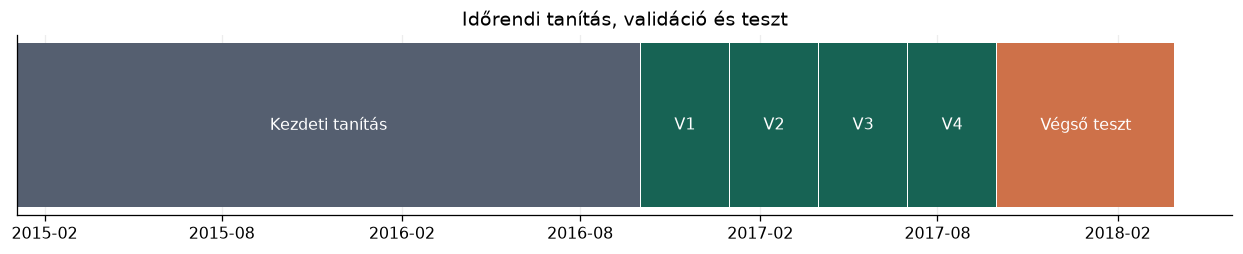

In [27]:
teszt_hetek = hetek[-26:]
valid_hetek = hetek[-78:-26]
valid_ablakok = [valid_hetek[i:i + 13] for i in range(0, len(valid_hetek), 13)]
kezdeti_hetek = hetek[:-78]
teszt_kezdete = teszt_hetek[0]

fig, ax = plt.subplots(figsize=(10.7, 2.1), layout="constrained")
szakaszok = [kezdeti_hetek, *valid_ablakok, teszt_hetek]
cimkek = ["Kezdeti tanítás", "V1", "V2", "V3", "V4", "Végső teszt"]
for szakasz, cim, szin in zip(szakaszok, cimkek, [SZURKE, ZOLD, ZOLD, ZOLD, ZOLD, NARANCS]):
    hossz = (szakasz[-1] - szakasz[0]).days + 6
    ax.barh(0, hossz, left=szakasz[0], color=szin, height=0.46)
    ax.text(szakasz[0] + pd.Timedelta(days=hossz / 2), 0, cim, color="white", ha="center", va="center")
    print(f"{cim:17} {szakasz[0].date()} – {szakasz[-1].date()} ({len(szakasz)} hét)")
ax.set(title="Időrendi tanítás, validáció és teszt", yticks=[])
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.show()